**Predicting Caffeine Crash Risk Using Machine Learning**

**Objective**: Predict individual caffeine crash risk based on caffeine consumption patterns and personal characteristics.

**Task**: Multiclass classification (4 classes)

**Models**: Logistic Regression, Decision Tree, Random Forest, XGBoost

**Evaluation metric**: Macro F1-score

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

## 1. Import dataset

In [2]:
data = pd.read_csv('data/caffeine_crash_and_anxiety_telemetry.csv') 

In [3]:
data.head()

,user_id,age,gender,cyp1a2_metabolizer_type,caffeine_tolerance,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,primary_caffeine_source,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score,crash_risk_level
0,CAF-00001,27,Female,Fast,High,2.4,7.0,2.29,Brewed Drip Coffee,138,8.7,36,2.0,1.0,1.0,7.5,4.1,Mild Afternoon Fatigue
1,CAF-00002,57,Female,Fast,Low,9.1,7.1,2.41,Energy Drink (Sugar-Free),164,0.0,3,2.4,2.0,5.5,7.5,2.5,Sustained / Negligible Crash
2,CAF-00003,39,Male,Normal,Low,2.9,5.1,2.07,Energy Drink (Full Sugar),179,36.9,10,3.8,4.8,5.5,3.6,7.9,Moderate Crash & Lethargy
3,CAF-00004,34,Female,Fast,Moderate,3.8,5.0,2.34,Pre-Workout Supplement,408,1.6,3,6.8,4.2,7.3,7.5,10.0,Severe Crash & Tachycardia
4,CAF-00005,22,Female,Slow,High,2.0,6.3,1.92,Energy Drink (Full Sugar),170,50.2,11,2.0,2.0,1.1,2.6,10.0,Severe Crash & Tachycardia


## 2. Data Cleaning & Feature selection

In [4]:
# samples (rows) and feature (columns)
print(f"Number of samples: {len(data)}")
print(f"Number of features: {len(data.columns)}")

Number of samples: 8000
Number of features: 18


In [5]:
data.isnull().sum()

user_id                     0
age                         0
gender                      0
cyp1a2_metabolizer_type     0
caffeine_tolerance          0
baseline_anxiety_score      0
prior_sleep_hours           0
daily_hydration_liters      0
primary_caffeine_source     0
caffeine_mg                 0
sugar_grams                 0
consumption_duration_min    0
heart_rate_spike_bpm        0
jitters_intensity_score     0
acute_anxiety_score         0
crash_onset_hours           0
crash_severity_score        0
crash_risk_level            0
dtype: int64

In [6]:
data.describe()

,age,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,caffeine_mg,sugar_grams,consumption_duration_min,heart_rate_spike_bpm,jitters_intensity_score,acute_anxiety_score,crash_onset_hours,crash_severity_score
count,8000.000000,8000.00000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,32.950875,3.48855,6.375550,2.108222,198.044125,18.026025,28.976250,4.669675,3.323437,3.683588,5.648900,6.294100
std,11.513711,2.07950,1.292857,0.783542,65.865873,19.132112,20.488751,4.004456,2.310030,2.370665,1.394713,2.334954
min,18.000000,1.00000,3.200000,0.600000,40.000000,0.000000,3.000000,2.000000,1.000000,1.000000,1.500000,1.000000
25%,24.000000,1.80000,5.500000,1.560000,157.000000,0.800000,10.000000,2.000000,1.300000,1.700000,4.500000,4.600000
50%,30.000000,3.00000,6.400000,2.110000,195.000000,10.500000,26.000000,2.500000,2.700000,3.200000,5.700000,6.400000
75%,40.000000,4.60000,7.300000,2.650000,234.000000,34.600000,45.000000,6.200000,4.500000,5.100000,6.900000,8.100000
max,65.000000,9.50000,9.500000,4.800000,420.000000,62.000000,107.000000,35.700000,10.000000,10.000000,7.500000,10.000000


In [7]:
data.dtypes

user_id                         str
age                           int64
gender                          str
cyp1a2_metabolizer_type         str
caffeine_tolerance              str
baseline_anxiety_score      float64
prior_sleep_hours           float64
daily_hydration_liters      float64
primary_caffeine_source         str
caffeine_mg                   int64
sugar_grams                 float64
consumption_duration_min      int64
heart_rate_spike_bpm        float64
jitters_intensity_score     float64
acute_anxiety_score         float64
crash_onset_hours           float64
crash_severity_score        float64
crash_risk_level                str
dtype: object

### target distribution

,Count
crash_risk_level,
Moderate Crash & Lethargy,2426
Mild Afternoon Fatigue,2377
Severe Crash & Tachycardia,2161
Sustained / Negligible Crash,1036


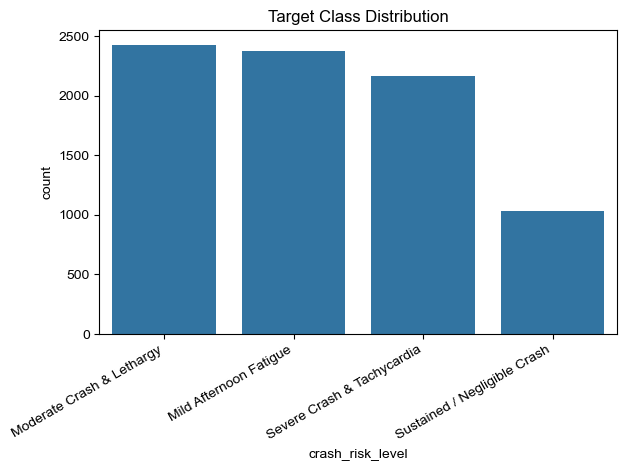

In [8]:
target = "crash_risk_level"

display(
    data[target].value_counts().to_frame("Count")
)

sns.countplot(
    data=data,
    x=target,
    order=data[target].value_counts().index
)

plt.xticks(rotation=30, ha="right")
plt.title("Target Class Distribution")
plt.tight_layout()
plt.show()

### select features

In [9]:
numeric_features = [
    "age",
    "baseline_anxiety_score",
    "prior_sleep_hours",
    "daily_hydration_liters",
    "caffeine_mg",
    "sugar_grams",
    "consumption_duration_min"
]

categorical_features = [
    "gender",
    "cyp1a2_metabolizer_type",
    "caffeine_tolerance",
    "primary_caffeine_source"
]

target = "crash_risk_level"

features = numeric_features + categorical_features

### create X and y

In [10]:
X = data[features].copy()
y = data[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

display(X.head())

X shape: (8000, 11)
y shape: (8000,)


,age,baseline_anxiety_score,prior_sleep_hours,daily_hydration_liters,caffeine_mg,sugar_grams,consumption_duration_min,gender,cyp1a2_metabolizer_type,caffeine_tolerance,primary_caffeine_source
0,27,2.4,7.0,2.29,138,8.7,36,Female,Fast,High,Brewed Drip Coffee
1,57,9.1,7.1,2.41,164,0.0,3,Female,Fast,Low,Energy Drink (Sugar-Free)
2,39,2.9,5.1,2.07,179,36.9,10,Male,Normal,Low,Energy Drink (Full Sugar)
3,34,3.8,5.0,2.34,408,1.6,3,Female,Fast,Moderate,Pre-Workout Supplement
4,22,2.0,6.3,1.92,170,50.2,11,Female,Slow,High,Energy Drink (Full Sugar)


In [11]:
print("Missing values:")
display(X.isna().sum())

print("\nCategorical variables:")
for col in categorical_features:
    print(f"{col}: {X[col].unique()}")

print("\nTarget classes:")
print(y.value_counts())

Missing values:


age                         0
baseline_anxiety_score      0
prior_sleep_hours           0
daily_hydration_liters      0
caffeine_mg                 0
sugar_grams                 0
consumption_duration_min    0
gender                      0
cyp1a2_metabolizer_type     0
caffeine_tolerance          0
primary_caffeine_source     0
dtype: int64


Categorical variables:
gender: <ArrowStringArray>
['Female', 'Male', 'Non-Binary']
Length: 3, dtype: str
cyp1a2_metabolizer_type: <ArrowStringArray>
['Fast', 'Normal', 'Slow']
Length: 3, dtype: str
caffeine_tolerance: <ArrowStringArray>
['High', 'Low', 'Moderate']
Length: 3, dtype: str
primary_caffeine_source: <ArrowStringArray>
[         'Brewed Drip Coffee',   'Energy Drink (Sugar-Free)',
   'Energy Drink (Full Sugar)',      'Pre-Workout Supplement',
 'Espresso / Specialty Drinks',          'Matcha / Green Tea']
Length: 6, dtype: str

Target classes:
crash_risk_level
Moderate Crash & Lethargy       2426
Mild Afternoon Fatigue          2377
Severe Crash & Tachycardia      2161
Sustained / Negligible Crash    1036
Name: count, dtype: int64


### check numerical distributions

,count,mean,std,min,25%,50%,75%,max
age,8000.0,32.950875,11.513711,18.0,24.00,30.00,40.00,65.0
baseline_anxiety_score,8000.0,3.488550,2.079500,1.0,1.80,3.00,4.60,9.5
prior_sleep_hours,8000.0,6.375550,1.292857,3.2,5.50,6.40,7.30,9.5
daily_hydration_liters,8000.0,2.108222,0.783542,0.6,1.56,2.11,2.65,4.8
caffeine_mg,8000.0,198.044125,65.865873,40.0,157.00,195.00,234.00,420.0
sugar_grams,8000.0,18.026025,19.132112,0.0,0.80,10.50,34.60,62.0
consumption_duration_min,8000.0,28.976250,20.488751,3.0,10.00,26.00,45.00,107.0


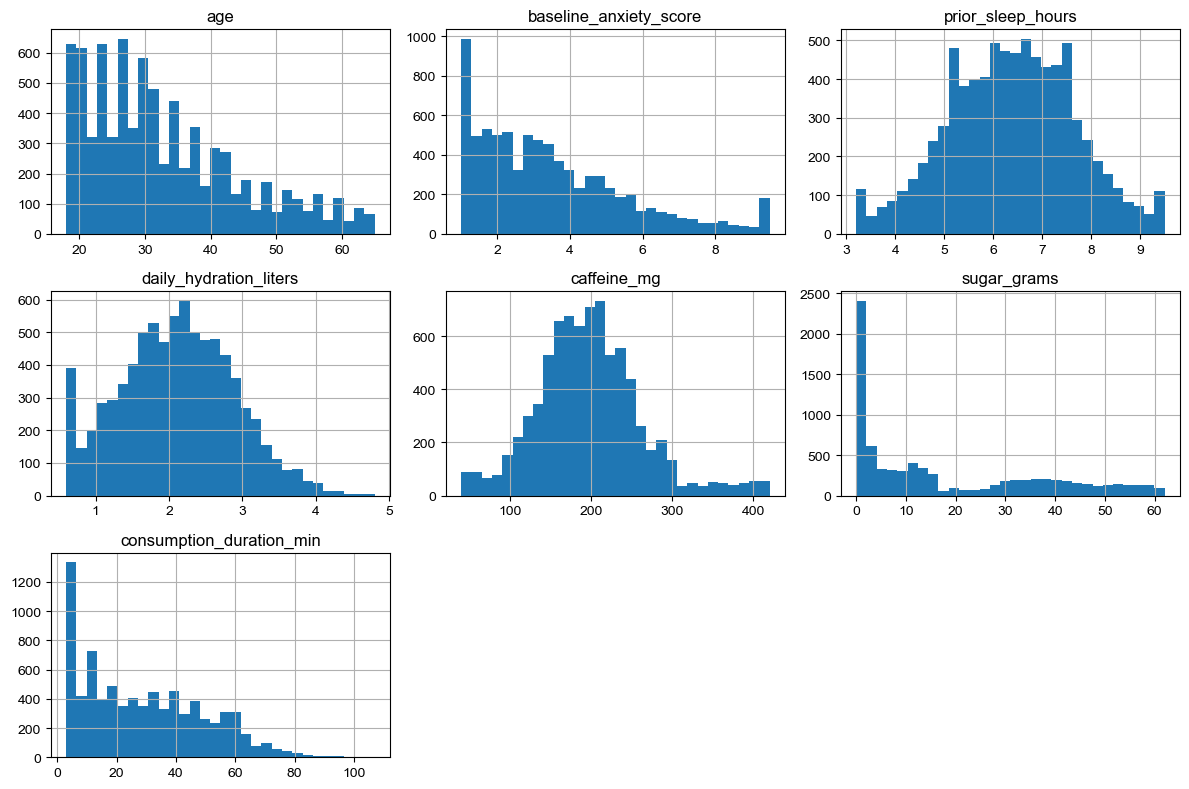

In [12]:
display(X[numeric_features].describe().T)

X[numeric_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

## 3. EDA

### correlation heatmap

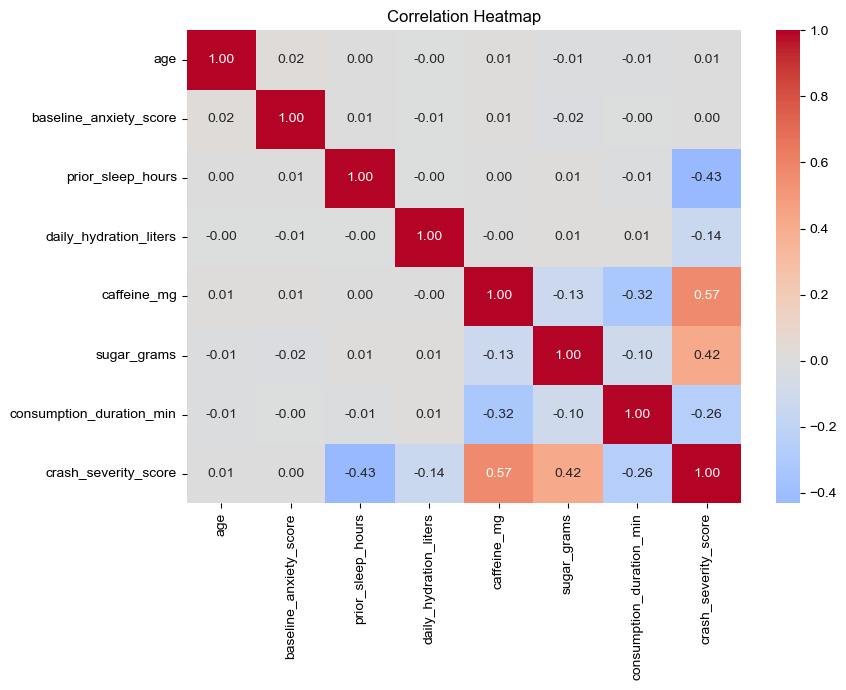

In [13]:
corr = data[numeric_features + ["crash_severity_score"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

### numerical vs. crash severity

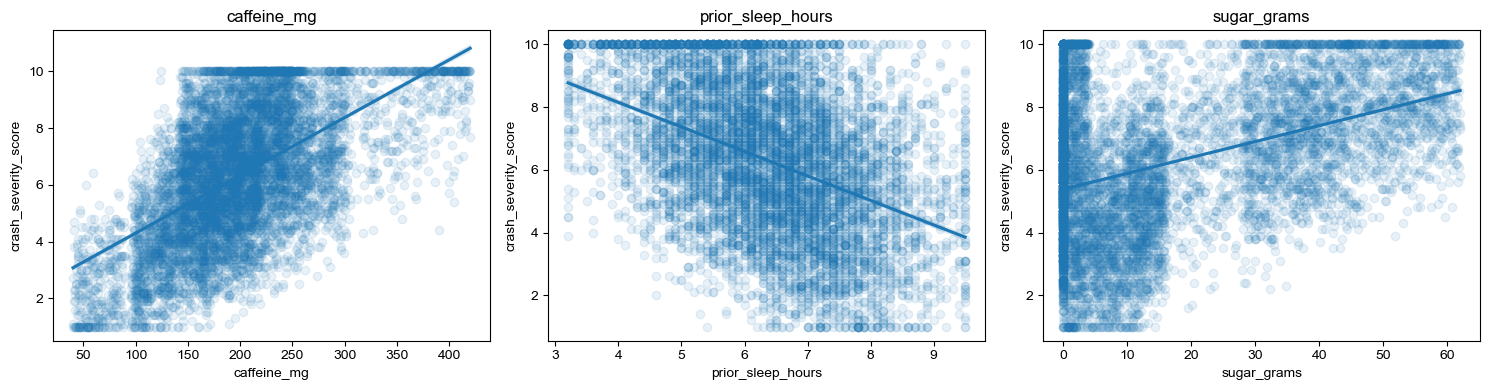

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(
    axes,
    ["caffeine_mg", "prior_sleep_hours", "sugar_grams"]
):
    sns.regplot(
        data=data, x=col, y="crash_severity_score",
        scatter_kws={"alpha": 0.1},
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

### categorical features vs. crash severity

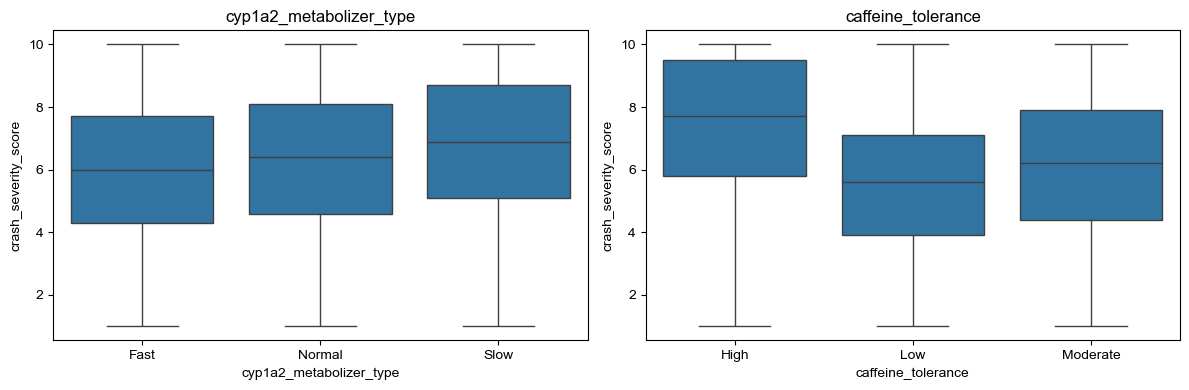

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(
    axes,
    ["cyp1a2_metabolizer_type", "caffeine_tolerance"]
):
    sns.boxplot(
        data=data, x=col, y="crash_severity_score",
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

## 4. Data split & Preprocessing

In [16]:
from sklearn.model_selection import train_test_split

# Train 60%, Validation + Test 40%
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.4,
    stratify=y,
    random_state=42
)

# Validation 20%, Test 20%
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.5,
    stratify=y_temp,
    random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (4800, 11)
Validation: (1600, 11)
Test: (1600, 11)


### preprocessing pipeline

In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
])

In [18]:
class_dist = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True)
})

display((class_dist * 100).round(2))

,Train,Validation,Test
crash_risk_level,,,
Moderate Crash & Lethargy,30.33,30.31,30.31
Mild Afternoon Fatigue,29.71,29.69,29.75
Severe Crash & Tachycardia,27.00,27.06,27.00
Sustained / Negligible Crash,12.96,12.94,12.94


## 5. Model Training & Comparison

In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder
from sklearn.base import clone

In [20]:
encoder = LabelEncoder()

y_train_enc = encoder.fit_transform(y_train)
y_val_enc = encoder.transform(y_val)
y_test_enc = encoder.transform(y_test)

print(encoder.classes_)

['Mild Afternoon Fatigue' 'Moderate Crash & Lethargy'
 'Severe Crash & Tachycardia' 'Sustained / Negligible Crash']


In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=200,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )
}

In [22]:
results = []
trained_models = {}

for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipe.fit(X_train, y_train_enc)
    pred = pipe.predict(X_val)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val_enc, pred),
        "Macro F1": f1_score(y_val_enc, pred, average="macro")
    })

    trained_models[name] = pipe

results_df = (
    pd.DataFrame(results)
    .sort_values("Macro F1", ascending=False)
)

display(results_df.round(4))

,Model,Accuracy,Macro F1
0,Logistic Regression,0.7994,0.7975
3,XGBoost,0.7512,0.7532
2,Random Forest,0.7319,0.7363
1,Decision Tree,0.6406,0.6471


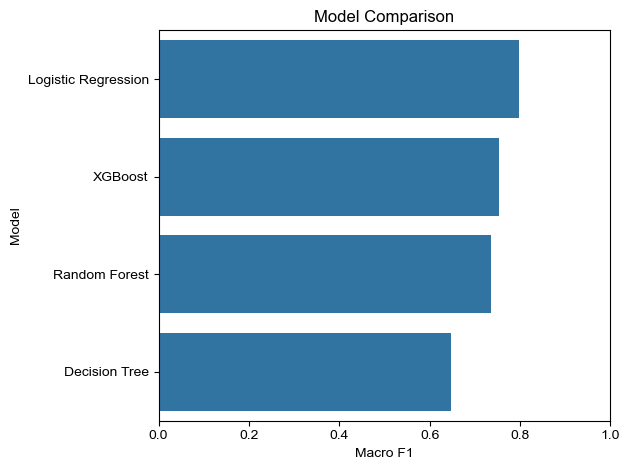

Best baseline model: Logistic Regression


In [23]:
sns.barplot(
    data=results_df,
    x="Macro F1",
    y="Model"
)

plt.title("Model Comparison")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best baseline model:", best_name)

### Define hyperparameters

In [24]:
from sklearn.model_selection import RandomizedSearchCV

param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100]
    },
    "Decision Tree": {
        "model__max_depth": [3, 5, 10, 15, None],
        "model__min_samples_leaf": [1, 5, 10, 20]
    },
    "Random Forest": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [5, 10, 20, None],
        "model__min_samples_leaf": [1, 5, 10]
    },
    "XGBoost": {
        "model__n_estimators": [100, 200, 300],
        "model__max_depth": [3, 5, 7],
        "model__learning_rate": [0.01, 0.05, 0.1],
        "model__subsample": [0.8, 1.0]
    }
}

### Run hyperparamter tuning

In [25]:
search = RandomizedSearchCV(
    estimator=clone(best_model),
    param_distributions=param_grids[best_name],
    n_iter=10,
    scoring="f1_macro",
    cv=5,
    random_state=42,
    n_jobs=-1
)

search.fit(X_train, y_train_enc)

print("Best parameters:", search.best_params_)
print("Best CV Macro F1:", round(search.best_score_, 4))

/home/bio/miniconda3/envs/py311/lib/python3.11/site-packages/sklearn/model_selection/_search.py:326: UserWarning: The total space of parameters 5 is smaller than n_iter=10. Running 5 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Best parameters: {'model__C': 1}
Best CV Macro F1: 0.7762


In [26]:
tuned_model = search.best_estimator_

pred_before = best_model.predict(X_val)
pred_after = tuned_model.predict(X_val)

comparison = pd.DataFrame({
    "Model": ["Before tuning", "After tuning"],
    "Accuracy": [
        accuracy_score(y_val_enc, pred_before),
        accuracy_score(y_val_enc, pred_after)
    ],
    "Macro F1": [
        f1_score(y_val_enc, pred_before, average="macro"),
        f1_score(y_val_enc, pred_after, average="macro")
    ]
})

display(comparison.round(4))

,Model,Accuracy,Macro F1
0,Before tuning,0.7994,0.7975
1,After tuning,0.7994,0.7975


In [27]:
f1_before = f1_score(y_val_enc, pred_before, average="macro")
f1_after = f1_score(y_val_enc, pred_after, average="macro")

final_model = tuned_model if f1_after > f1_before else best_model

print("Final model:", best_name)
print("Validation Macro F1:", round(max(f1_before, f1_after), 4))

Final model: Logistic Regression
Validation Macro F1: 0.7975


### select final model

In [28]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

y_pred = final_model.predict(X_test)

print("Test Accuracy:", round(accuracy_score(y_test_enc, y_pred), 4))
print("Test Macro F1:", round(f1_score(y_test_enc, y_pred, average="macro"), 4))

print(classification_report(
    y_test_enc,
    y_pred,
    target_names=encoder.classes_
))

Test Accuracy: 0.7769
Test Macro F1: 0.7844
                              precision    recall  f1-score   support

      Mild Afternoon Fatigue       0.77      0.73      0.75       476
   Moderate Crash & Lethargy       0.70      0.75      0.72       485
  Severe Crash & Tachycardia       0.86      0.85      0.86       432
Sustained / Negligible Crash       0.82      0.80      0.81       207

                    accuracy                           0.78      1600
                   macro avg       0.79      0.78      0.78      1600
                weighted avg       0.78      0.78      0.78      1600



## 6. Final model evaluation & feature importance

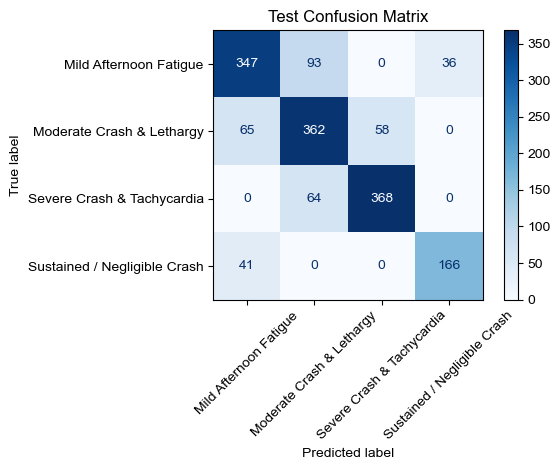

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_test_enc,
    y_pred,
    display_labels=encoder.classes_,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Test Confusion Matrix")
plt.tight_layout()
plt.show()

In [30]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    final_model,
    X_val,
    y_val_enc,
    scoring="f1_macro",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

,Feature,Importance
4,caffeine_mg,0.355325
2,prior_sleep_hours,0.285177
5,sugar_grams,0.263665
9,caffeine_tolerance,0.150953
3,daily_hydration_liters,0.055948
8,cyp1a2_metabolizer_type,0.033472
10,primary_caffeine_source,0.005200
6,consumption_duration_min,0.002296
7,gender,-0.000591
1,baseline_anxiety_score,-0.003168


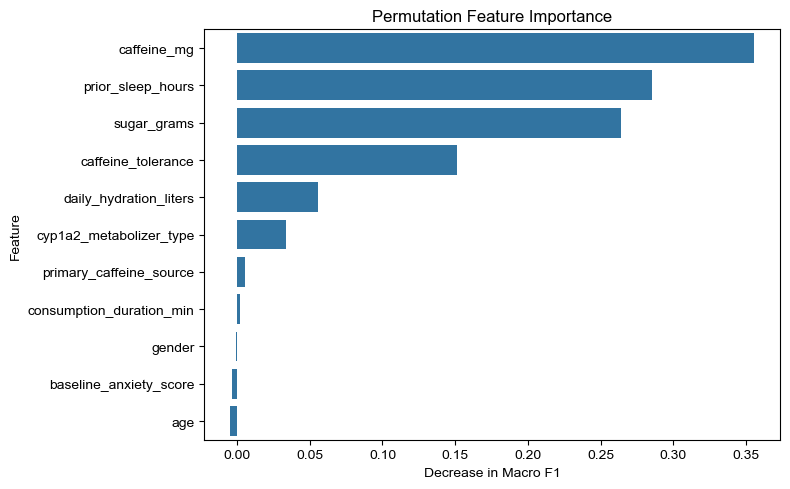

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Permutation Feature Importance")
plt.xlabel("Decrease in Macro F1")
plt.tight_layout()
plt.show()

## 7. Save final model

In [32]:
import joblib
from pathlib import Path

Path("model").mkdir(exist_ok=True)

joblib.dump(
    {
        "model": final_model,
        "classes": encoder.classes_.tolist(),
        "features": features
    },
    "model/model.pkl"
)

print("Model saved to model/model.pkl")

Model saved to model/model.pkl
